In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [25]:
df = pd.read_csv('World_Happiness_2015.csv')

In [26]:
df.head(3)

,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204


In [27]:
df.groupby('Region')['Happiness Score'].mean()

Region
Australia and New Zealand          7.285000
Central and Eastern Europe         5.332931
Eastern Asia                       5.626167
Latin America and Caribbean        6.144682
Middle East and Northern Africa    5.406900
North America                      7.273000
Southeastern Asia                  5.317444
Southern Asia                      4.580857
Sub-Saharan Africa                 4.202800
Western Europe                     6.689619
Name: Happiness Score, dtype: float64

In [28]:
df.groupby('Region')['Happiness Score'].agg([np.mean,np.max,np.min])

,mean,max,min
Region,,,
Australia and New Zealand,7.285000,7.286,7.284
Central and Eastern Europe,5.332931,6.505,4.218
Eastern Asia,5.626167,6.298,4.874
Latin America and Caribbean,6.144682,7.226,4.518
Middle East and Northern Africa,5.406900,7.278,3.006
North America,7.273000,7.427,7.119
Southeastern Asia,5.317444,6.798,3.819
Southern Asia,4.580857,5.253,3.575
Sub-Saharan Africa,4.202800,5.477,2.839


In [29]:
def diff(group):
    return group.max() - group.min()

In [30]:
df.groupby('Region')['Happiness Score'].agg(diff)

Region
Australia and New Zealand          0.002
Central and Eastern Europe         2.287
Eastern Asia                       1.424
Latin America and Caribbean        2.708
Middle East and Northern Africa    4.272
North America                      0.308
Southeastern Asia                  2.979
Southern Asia                      1.678
Sub-Saharan Africa                 2.638
Western Europe                     2.730
Name: Happiness Score, dtype: float64

In [31]:
happiness_means = df.groupby('Region')['Happiness Score'].mean()
print(happiness_means.index)
print(happiness_means.values)

Index(['Australia and New Zealand', 'Central and Eastern Europe',
       'Eastern Asia', 'Latin America and Caribbean',
       'Middle East and Northern Africa', 'North America', 'Southeastern Asia',
       'Southern Asia', 'Sub-Saharan Africa', 'Western Europe'],
      dtype='str', name='Region')
[7.285      5.33293103 5.62616667 6.14468182 5.4069     7.273
 5.31744444 4.58085714 4.2028     6.68961905]


In [32]:
happiness_means

Region
Australia and New Zealand          7.285000
Central and Eastern Europe         5.332931
Eastern Asia                       5.626167
Latin America and Caribbean        6.144682
Middle East and Northern Africa    5.406900
North America                      7.273000
Southeastern Asia                  5.317444
Southern Asia                      4.580857
Sub-Saharan Africa                 4.202800
Western Europe                     6.689619
Name: Happiness Score, dtype: float64

In [33]:
df.pivot_table(index='Region', values='Happiness Score',aggfunc=np.mean)

,Happiness Score
Region,
Australia and New Zealand,7.285000
Central and Eastern Europe,5.332931
Eastern Asia,5.626167
Latin America and Caribbean,6.144682
Middle East and Northern Africa,5.406900
North America,7.273000
Southeastern Asia,5.317444
Southern Asia,4.580857
Sub-Saharan Africa,4.202800


In [34]:
pv_happiness = df.pivot_table(index='Region', values='Happiness Score',aggfunc=np.mean,margins=True)

In [39]:
df['Happiness Score'].mean()

np.float64(5.375734177215189)

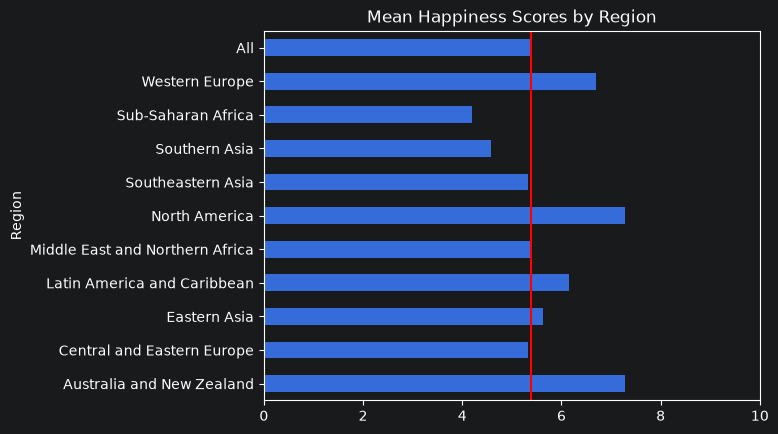

In [40]:
pv_happiness.plot(
    kind='barh',
    xlim=(0,10),
    title='Mean Happiness Scores by Region',
    legend=False
)

plt.axvline(x=df['Happiness Score'].mean(), color='red')

plt.show()

In [37]:
world_mean_happiness = df['Happiness Score'].mean()